# Enterprise Data Architecture & Reconciliation

## The Scenario
You are a Senior Data Analyst at a massive FinTech company. The Data Engineering team is on vacation, and the CFO needs the Q1-Q4 Financial Audit Dashboard by Friday.

You have been given access to three separate, messy systems:
1. **The HR Database (`enterprise_database.db`):** A SQL database containing user accounts. *Warning: It contains historical logs, meaning users appear multiple times. You only want their most recent status.*
2. **The Server Logs (`server_logs.txt`):** 100,000 raw text logs. The transaction data is trapped inside strings.
3. **The Finance Server (`daily_exchange_rates.csv`):** A list of daily EUR to USD exchange rates. *Warning: The financial market is closed on weekends, so weekend dates have missing exchange rates.*

## Your Mission
You must architect a Python pipeline to extract, clean, merge, and visualize this data.

**Requirements for Passing:**
1. **Advanced SQL:** Extract only "Active" users from the database using the most recent `updated_at` timestamp.
2. **String Manipulation (Regex):** Extract the Date, User ID, Product ID, and Euro Value from the raw text logs. Filter out rows labeled "ERROR".
3. **Temporal Joins:** Join the transactions to the exchange rate table based on the exact day. You must forward-fill the weekend exchange rates so transactions don't drop out.
4. **Efficiency:** Your code must run on all 100,000 rows in under 2 minutes. No `for` loops allowed in Pandas.
5. **Dashboard:** Build visualizations showing Total USD Revenue by Month and Top 5 Most Valuable Customers.

In [7]:
# ===================================================================
# PHASE 1: SQL EXTRACTION
# ===================================================================
import sqlite3
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
# 1. Connect to 'enterprise_database.db'
# 2. Write a SQL query (using Window Functions or Subqueries) to get the most
#    recent status for each user.
# 3. Only keep users whose latest status is 'Active'.
# 4. Load the result into a Pandas DataFrame called 'df_active_users'.

# [WRITE YOUR SQL AND PYTHON CODE HERE]

DB_PATH = Path("enterprise_database (1).db")
LOG_PATH = Path("server_logs (1).txt")
RATES_PATH = Path("daily_exchange_rates (1).csv")



sql = """
WITH latest_users AS (
    SELECT
        user_id,
        name,
        status,
        updated_at,
        ROW_NUMBER() OVER (
            PARTITION BY user_id
            ORDER BY updated_at DESC
        ) AS row_num

    FROM users
)

SELECT
    user_id,
    name,
    status,
    updated_at

FROM latest_users
WHERE row_num = 1
AND status = 'Active';
"""


with sqlite3.connect(DB_PATH) as connection:
    df_active_users = pd.read_sql_query(sql, connection)


print("Latest Active users:", len(df_active_users))

df_active_users.head()



Latest Active users: 14183


,user_id,name,status,updated_at
0,U-00001,User_U-00001,Active,2023-01-28 14:00:00
1,U-00003,User_U-00003,Active,2023-01-22 14:00:00
2,U-00005,User_U-00005,Active,2023-01-17 14:00:00
3,U-00006,User_U-00006,Active,2023-01-05 14:00:00
4,U-00007,User_U-00007,Active,2023-01-27 14:00:00


In [8]:
# ===================================================================
# PHASE 2: REGEX & UNSTRUCTURED DATA WRANGLING
# ===================================================================

# 1. Load 'server_logs.txt' into a DataFrame.
# 2. Drop any rows where the log contains the word "ERROR".
# 3. Use Pandas string methods (.str.extract()) or Python Regex to pull the
#    Date, User ID, Product ID, and Euro Value out of the raw text string.
# 4. Save this cleaned data to a new DataFrame called 'extracted_data'.

# [WRITE YOUR REGEX AND CLEANING CODE HERE]

df_logs = pd.read_csv(
    LOG_PATH,
    skiprows=1,
    header=None,
    names=["raw"],
    quotechar='"',
    doublequote=True
)


df_logs = df_logs[
    ~df_logs["raw"].str.contains(r"\bERROR\b", na=False)
].copy()

pattern = (
    r'^\[(?P<Date>\d{4}-\d{2}-\d{2}) \d{2}:\d{2}:\d{2}\] '
    r'INFO:.*?"u":"(?P<User_ID>[^"]+)".*?'
    r'"item_code":"(?P<Product_ID>[^"]+)".*?'
    r'"eur_val":(?P<EUR_Value>[\d.]+)'
)


extracted_data = df_logs["raw"].str.extract(pattern)


extracted_data["Date"] = pd.to_datetime(
    extracted_data["Date"],
    errors="coerce"
)


extracted_data["EUR_Value"] = pd.to_numeric(
    extracted_data["EUR_Value"],
    errors="coerce"
)


extracted_data = extracted_data.dropna().copy()


print(
    "Successful transactions extracted:",
    len(extracted_data)
)

extracted_data.head()

Successful transactions extracted: 94902


,Date,User_ID,Product_ID,EUR_Value
0,2023-03-15,U-19484,PRD-874,3404.44
2,2023-05-09,U-18932,PRD-905,3406.21
3,2023-10-21,U-15882,PRD-284,164.08
4,2023-01-10,U-22781,PRD-665,26.80
5,2023-05-23,U-13348,PRD-589,4964.77


In [9]:
# ===================================================================
# PHASE 3: FINANCIAL RECONCILIATION & MERGING
# ===================================================================

# 1. Load 'daily_exchange_rates.csv' into a DataFrame.
# 2. Handle the missing weekend data using a method like .fillna(method='ffill')
#    so Friday's rate rolls over to Saturday and Sunday.
# 3. Merge your cleaned logs with the exchange rates by Date.
# 4. Merge that result with your active SQL users by User ID.
# 5. Calculate a new column called 'USD_Revenue' (Euro Value * Exchange Rate).
# 6. Save the final merged table as 'df_final'.

# [WRITE YOUR MERGING AND MATH CODE HERE]

df_rates = pd.read_csv(
    RATES_PATH,
    parse_dates=["Date"]
)


df_rates = df_rates.sort_values("Date")

# Filling missing exchange rates using the previous available rate

df_rates["EUR_to_USD"] = df_rates["EUR_to_USD"].ffill()

# Combining transactions with exchange rates

df_final = extracted_data.merge(
    df_rates,
    on="Date",
    how="left"
)

# Keeping only transactions belonging to Active users

df_final = df_final.merge(
    df_active_users[["user_id", "name"]],
    left_on="User_ID",
    right_on="user_id",
    how="inner"
)

# Calculating revenue in USD

df_final["USD_Revenue"] = (
    df_final["EUR_Value"] * df_final["EUR_to_USD"]
)

# Removing the duplicate user ID column

df_final = df_final.drop(columns=["user_id"])


print("Final transaction rows:", len(df_final))

print(
    "Rows with missing exchange rate:",
    df_final["EUR_to_USD"].isna().sum()
)

print(
    "Total USD revenue:",
    round(df_final["USD_Revenue"].sum(), 2)
)


df_final.head()

Final transaction rows: 53899
Rows with missing exchange rate: 0
Total USD revenue: 148274622.91


,Date,User_ID,Product_ID,EUR_Value,EUR_to_USD,name,USD_Revenue
0,2023-03-15,U-19484,PRD-874,3404.44,1.178232,User_U-19484,4011.220772
1,2023-10-21,U-15882,PRD-284,164.08,1.075350,User_U-15882,176.443420
2,2023-01-10,U-22781,PRD-665,26.80,1.127128,User_U-22781,30.207030
3,2023-10-20,U-22062,PRD-363,48.63,1.075350,User_U-22062,52.294268
4,2023-12-02,U-22146,PRD-223,960.60,1.066142,User_U-22146,1024.135923


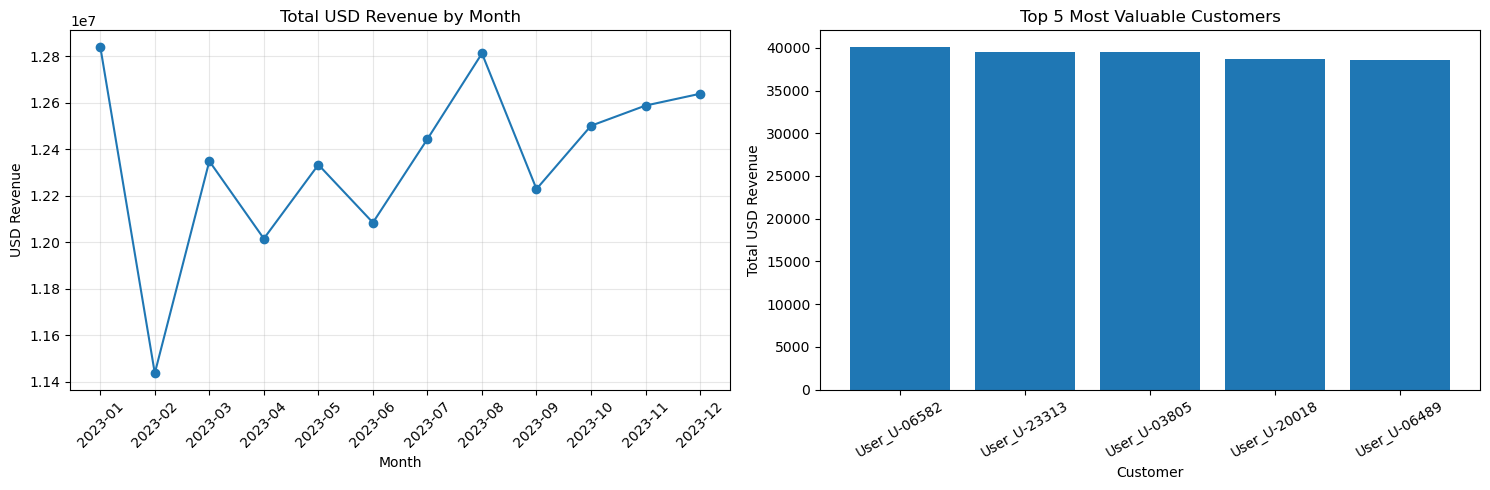

All project files saved successfully!


In [11]:
# ===================================================================
# PHASE 4: AGGREGATION & VISUALIZATION (CFO DASHBOARD)
# ===================================================================

# 1. Group the data in 'df_final' to calculate Total USD Revenue by Month.
# 2. Group the data to find the Top 5 Most Valuable Customers by Total USD spent.
# 3. Use Matplotlib or Seaborn to generate two charts side-by-side:
#    - Chart 1: A Line Chart or Bar Chart showing Revenue by Month.
#    - Chart 2: A Bar Chart showing the Top 5 Customers.
# 4. Ensure your charts have titles, clean axes, and are easy to read.

# [WRITE YOUR VISUALIZATION CODE HERE]


# Creating a Month column from the transaction Date

df_final["Month"] = (
    df_final["Date"].dt.to_period("M").astype(str)
)

# Calculating total revenue for each month

monthly_revenue = (
    df_final.groupby("Month", as_index=False)["USD_Revenue"]
    .sum()
    .sort_values("Month")
)

# Calculating the top 5 customers

top_customers = (
    df_final.groupby(
        ["User_ID", "name"],
        as_index=False
    )["USD_Revenue"]
    .sum()
    .sort_values(
        "USD_Revenue",
        ascending=False
    )
    .head(5)
)

# Creating two charts side by side

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# First chart: Monthly revenue

axes[0].plot(
    monthly_revenue["Month"],
    monthly_revenue["USD_Revenue"],
    marker="o"
)

axes[0].set_title("Total USD Revenue by Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("USD Revenue")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(True, alpha=0.3)

# Second chart: Top 5 customers

axes[1].bar(
    top_customers["name"],
    top_customers["USD_Revenue"]
)

axes[1].set_title("Top 5 Most Valuable Customers")
axes[1].set_xlabel("Customer")
axes[1].set_ylabel("Total USD Revenue")
axes[1].tick_params(axis="x", rotation=30)

# Adjusting chart layout

plt.tight_layout()


plt.show()

# Saving results as CSV files

df_final.to_csv(
    "final_reconciled_transactions.csv",
    index=False
)

monthly_revenue.to_csv(
    "monthly_usd_revenue.csv",
    index=False
)

top_customers.to_csv(
    "top_5_customers.csv",
    index=False
)

print("All project files saved successfully!")